# 04 · Análise exploratória (EDA)

Analisa as distribuições, os outliers, as correlações entre os atributos e a relação de cada atributo com a variável alvo, usando **somente o conjunto de treino**.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from scroll_sono.config import (BINARY_COLS, EXPECTED_DOMAINS, FIGURES_DIR, MOMENT, NOMINAL_COLS,
                                NUMERIC_COLS, ORDINAL_COLS, TARGET, TARGET_CLASSES)
from scroll_sono.data import load_train

In [2]:
# Estilo dos gráficos
SUPERFICIE, TEXTO, TEXTO_SECUNDARIO, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_SECUNDARIO, "axes.edgecolor": "#c3c2b7",
    "xtick.color": TEXTO_SECUNDARIO, "ytick.color": TEXTO_SECUNDARIO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titlelocation": "left", "figure.titlesize": 12,
    "font.size": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

# Classes do alvo: uma única cor, do mais claro (sem déficit) ao mais escuro (déficit grave)
CORES_CLASSES = dict(zip(TARGET_CLASSES, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))
# Grupos de atributos: os do cenário comportamental e os medidos durante/depois do sono
GRUPOS = {
    **{col: "perfil e antes de dormir" for col in MOMENT["perfil"] + MOMENT["antes de dormir"]},
    **{col: "durante o sono e dia seguinte" for col in MOMENT["durante o sono"] + MOMENT["dia seguinte"]},
}
CORES_GRUPOS = {"perfil e antes de dormir": "#2a78d6", "durante o sono e dia seguinte": "#eb6834"}
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#184f95", "#f0efec", "#b8302f"])
SEQUENCIAL = LinearSegmentedColormap.from_list("sequencial", ["#f0efec", "#86b6ef", "#256abf", "#0d366b"])


def legenda_grupos(fig, **kwargs):
    alcas = [plt.Rectangle((0, 0), 1, 1, color=cor) for cor in CORES_GRUPOS.values()]
    fig.legend(alcas, CORES_GRUPOS, ncols=2, frameon=False, **kwargs)


def legenda_classes(fig, **kwargs):
    alcas = [plt.Rectangle((0, 0), 1, 1, color=cor) for cor in CORES_CLASSES.values()]
    fig.legend(alcas, CORES_CLASSES, ncols=4, frameon=False, **kwargs)


def pct(valor: float, casas: int = 1) -> str:
    return f"{valor:.{casas}%}".replace(".", ",")


def salvar(fig, nome: str) -> None:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{nome}.png")

In [3]:
train = load_train()
print(f"Treino: {train.shape[0]:,} linhas × {train.shape[1]} colunas")

Treino: 6,800 linhas × 18 colunas


## 1. Variável alvo

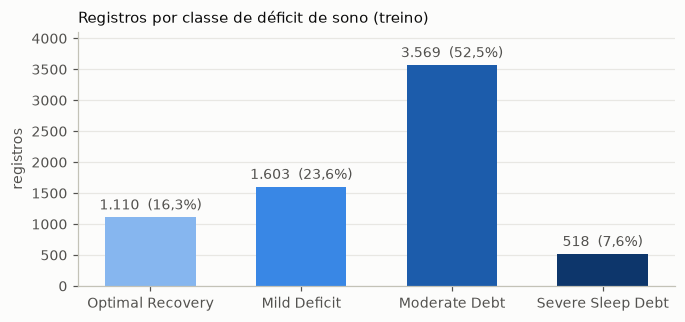

In [4]:
contagem = train[TARGET].value_counts().reindex(TARGET_CLASSES)

fig, ax = plt.subplots(figsize=(7, 3))
barras = ax.bar(contagem.index, contagem, color=list(CORES_CLASSES.values()), width=0.6)
ax.bar_label(barras, labels=[f"{n:,}".replace(",", ".") + f"  ({pct(n / len(train))})" for n in contagem],
             padding=3, color=TEXTO_SECUNDARIO)
ax.set_title("Registros por classe de déficit de sono (treino)")
ax.set_ylabel("registros")
ax.grid(axis="x", visible=False)
ax.margins(y=0.15)
salvar(fig, "04_alvo")

As classes são desbalanceadas: `Moderate Debt` reúne 52,5% dos registros e `Severe Sleep Debt` só 7,6%. Um classificador que sempre previsse `Moderate Debt` acertaria mais da metade, por isso a acurácia sozinha não basta para avaliar os modelos. A acurácia balanceada e o F1 macro dão o mesmo peso a cada classe.

## 2. Distribuições

### 2.1 Atributos numéricos

In [5]:
resumo = train[NUMERIC_COLS].describe().T[["mean", "std", "min", "50%", "max"]]
resumo["assimetria"] = train[NUMERIC_COLS].skew()
resumo["% de zeros"] = (train[NUMERIC_COLS] == 0).mean() * 100
resumo["% no mínimo"] = train[NUMERIC_COLS].eq(train[NUMERIC_COLS].min()).mean() * 100
resumo["% no máximo"] = train[NUMERIC_COLS].eq(train[NUMERIC_COLS].max()).mean() * 100
resumo.round(2)

,mean,std,min,50%,max,assimetria,% de zeros,% no mínimo,% no máximo
age,34.31,11.59,18.0,32.00,65.0,0.69,0.00,2.69,0.49
bedtime_phone_minutes,59.19,36.97,1.0,51.00,180.0,1.04,0.00,0.01,0.99
screen_brightness_pct,55.08,19.89,10.0,55.00,100.0,-0.00,0.00,1.35,1.46
caffeine_post_5pm_mg,32.98,52.02,0.0,0.00,250.0,1.80,58.69,58.69,0.62
physical_activity_min,35.77,20.85,0.0,35.00,112.0,0.27,5.53,5.53,0.01
sleep_latency_min,40.68,17.51,6.0,37.60,123.3,0.97,0.00,0.04,0.01
total_sleep_hours,6.27,1.44,3.2,6.32,9.8,-0.17,0.00,2.88,0.21
deep_sleep_pct,21.74,3.07,9.6,21.90,28.0,-0.25,0.00,0.01,1.90
rem_sleep_pct,19.11,2.55,9.6,19.20,27.0,-0.12,0.00,0.01,0.09
morning_alarm_snoozes,2.77,1.69,0.0,3.00,7.0,0.35,8.79,8.79,2.15


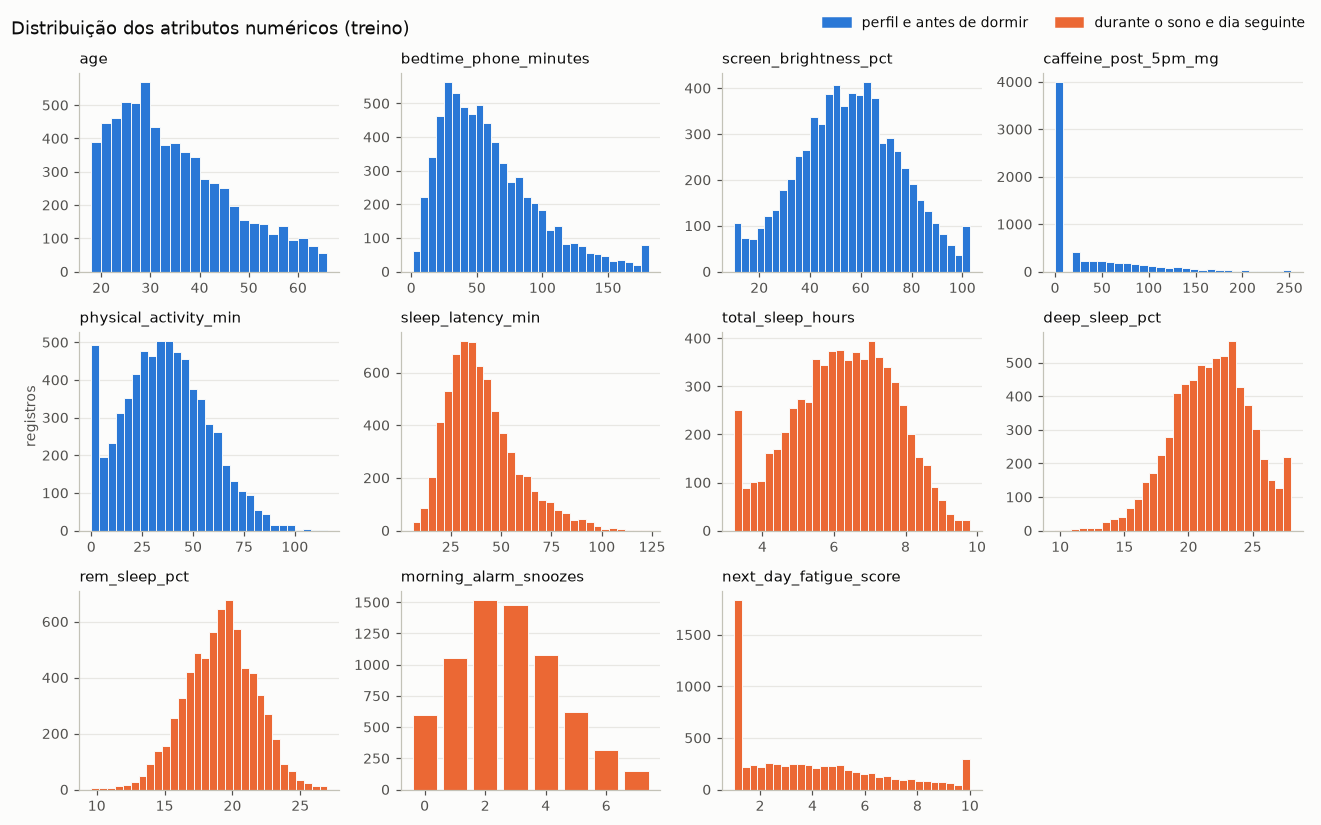

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(12, 7.5))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    minimo, maximo = train[col].min(), train[col].max()
    discreta = train[col].nunique() <= 10
    if discreta:
        bins = np.arange(minimo - 0.5, maximo + 1)
    elif (train[col] % 1 == 0).all():  # inteiros: classes de largura inteira, sem serrilhado
        largura = int(np.ceil((maximo - minimo) / 30))
        bins = np.arange(minimo, maximo + largura + 1, largura)
    else:
        bins = 30
    ax.hist(train[col], bins=bins, color=CORES_GRUPOS[GRUPOS[col]],
            edgecolor=SUPERFICIE, linewidth=0.6, rwidth=0.8 if discreta else None)
    ax.set_title(col)
    ax.grid(axis="x", visible=False)
axes.flat[-1].remove()
fig.suptitle("Distribuição dos atributos numéricos (treino)", x=0.01, ha="left")
legenda_grupos(fig, loc="upper right", bbox_to_anchor=(1, 1.0))
fig.supylabel("registros", color=TEXTO_SECUNDARIO, fontsize=9)
fig.tight_layout()
salvar(fig, "04_distribuicoes_numericas")

- `caffeine_post_5pm_mg` tem 58,7% de zeros e uma cauda longa à direita (assimetria de 1,80): a distribuição mistura quem não consome cafeína depois das 17h com quem consome.
- `bedtime_phone_minutes` e `sleep_latency_min` são assimétricas à direita (assimetria perto de 1).
- Vários atributos acumulam registros nos limites da faixa, sinal de que a simulação cortou os valores nesses pontos (*clipping*): `next_day_fatigue_score` tem 24,7% dos registros no mínimo (1,0) e 3,7% no máximo (10,0), `total_sleep_hours` tem 2,9% no mínimo (3,2 h), e `screen_brightness_pct`, `deep_sleep_pct` e `bedtime_phone_minutes` têm entre 1% e 2% dos registros nos extremos.
- `screen_brightness_pct`, `total_sleep_hours`, `deep_sleep_pct` e `rem_sleep_pct` são aproximadamente simétricas.

### 2.2 Atributos categóricos e binário

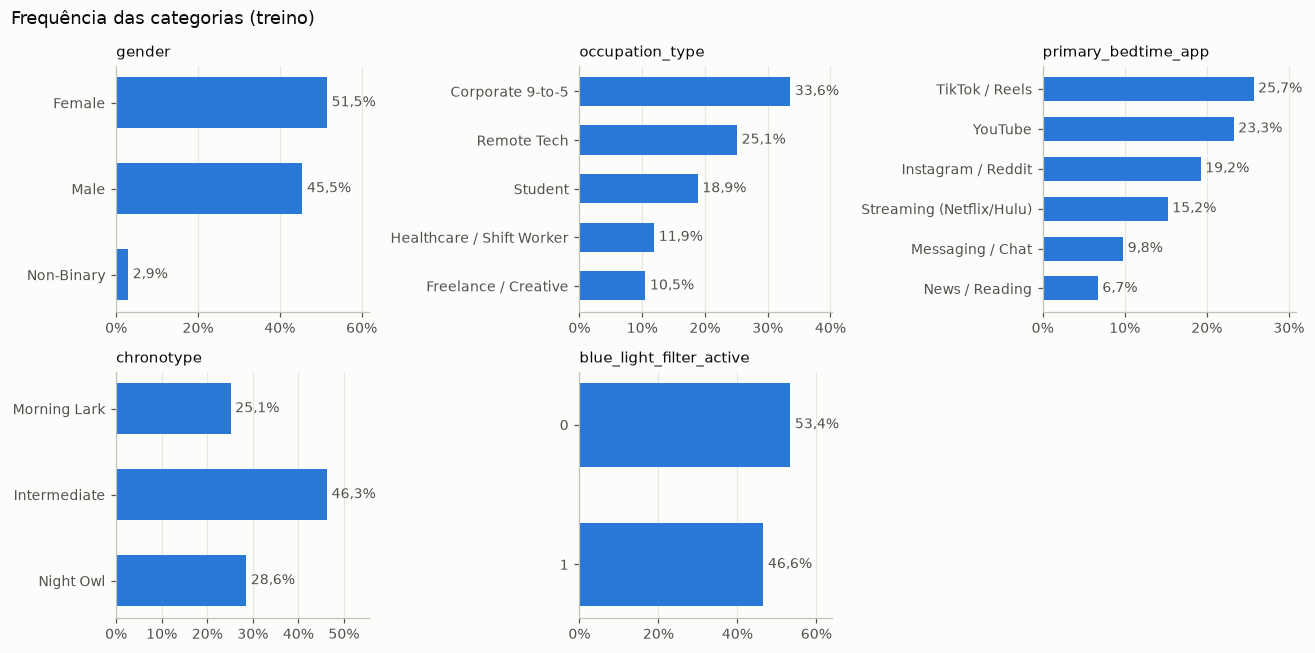

In [7]:
ordem = {col: categorias for col, categorias in ORDINAL_COLS.items()}
colunas_cat = NOMINAL_COLS + list(ORDINAL_COLS) + BINARY_COLS

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, colunas_cat):
    freq = train[col].value_counts(normalize=True)
    freq = freq.reindex(ordem[col][::-1]) if col in ordem else freq.sort_values()
    barras = ax.barh(freq.index.astype(str), freq, color=CORES_GRUPOS[GRUPOS[col]], height=0.6)
    ax.bar_label(barras, labels=[pct(p) for p in freq], padding=3, color=TEXTO_SECUNDARIO)
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(lambda x, _: pct(x, 0))
    ax.margins(x=0.2)
axes.flat[-1].remove()
fig.suptitle("Frequência das categorias (treino)", x=0.01, ha="left")
fig.tight_layout()
salvar(fig, "04_distribuicoes_categoricas")

- `gender` tem uma categoria rara: `Non-Binary`, com 2,9% dos registros.
- Nas demais categóricas, a menor categoria é `News / Reading`, com 6,7%.
- `blue_light_filter_active` é equilibrado: 46,6% dos registros têm o filtro ativo.

## 3. Outliers

Os outliers estatísticos são identificados pela regra do intervalo interquartil (IQR): valores abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR.

In [8]:
q1, q3 = train[NUMERIC_COLS].quantile(0.25), train[NUMERIC_COLS].quantile(0.75)
iqr = q3 - q1
limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
fora = train[NUMERIC_COLS].lt(limite_inf) | train[NUMERIC_COLS].gt(limite_sup)

outliers = pd.DataFrame({
    "limite inferior": limite_inf,
    "limite superior": limite_sup,
    "mínimo": train[NUMERIC_COLS].min(),
    "máximo": train[NUMERIC_COLS].max(),
    "outliers": fora.sum(),
    "% outliers": fora.mean() * 100,
}).sort_values("outliers", ascending=False)
outliers.round(2)

,limite inferior,limite superior,mínimo,máximo,outliers,% outliers
caffeine_post_5pm_mg,-81.00,135.00,0.0,250.0,412,6.06
sleep_latency_min,-4.05,81.95,6.0,123.3,201,2.96
bedtime_phone_minutes,-41.00,151.00,1.0,180.0,191,2.81
rem_sleep_pct,12.30,25.90,9.6,27.0,54,0.79
deep_sleep_pct,13.40,30.20,9.6,28.0,39,0.57
physical_activity_min,-22.50,93.50,0.0,112.0,32,0.47
age,-0.50,67.50,18.0,65.0,0,0.00
screen_brightness_pct,-1.00,111.00,10.0,100.0,0,0.00
total_sleep_hours,2.10,10.50,3.2,9.8,0,0.00
morning_alarm_snoozes,-1.00,7.00,0.0,7.0,0,0.00


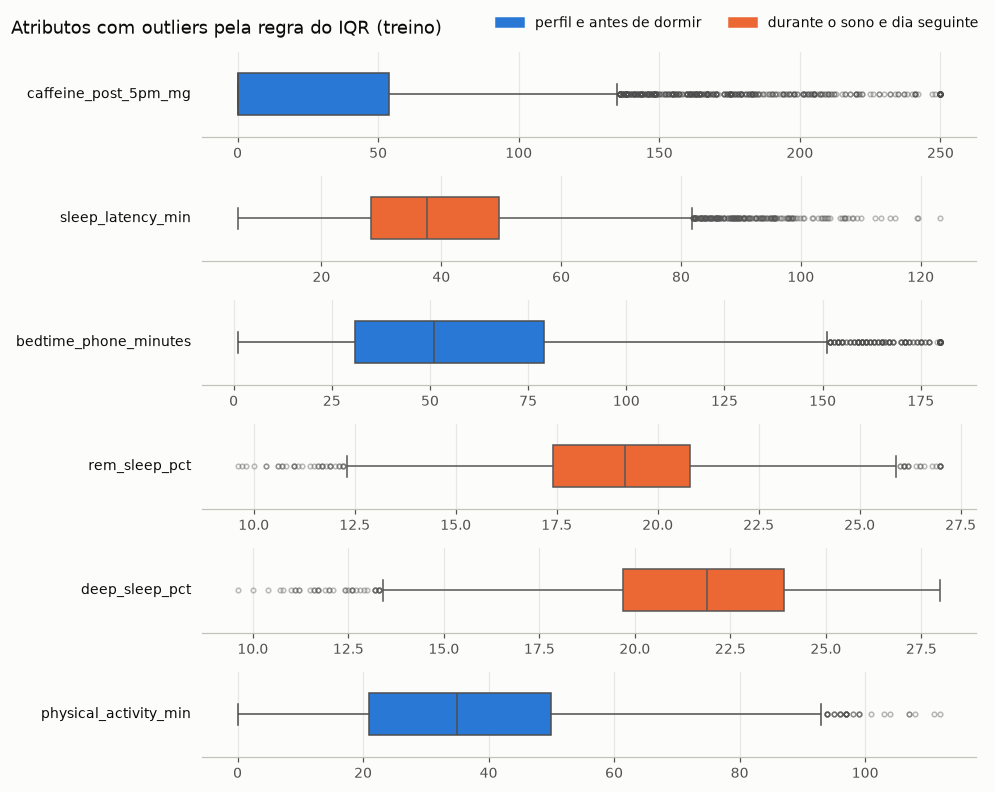

In [9]:
com_outliers = outliers.index[outliers["outliers"] > 0]

fig, axes = plt.subplots(len(com_outliers), 1, figsize=(9, 1.1 * len(com_outliers) + 0.6))
for ax, col in zip(axes, com_outliers):
    sns.boxplot(x=train[col], ax=ax, color=CORES_GRUPOS[GRUPOS[col]], saturation=1, width=0.5, linewidth=1,
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_xlabel("")
    ax.set_ylabel(col, rotation=0, ha="right", va="center", color=TEXTO)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Atributos com outliers pela regra do IQR (treino)", x=0.01, ha="left")
legenda_grupos(fig, loc="upper right", bbox_to_anchor=(1, 1.0))
fig.tight_layout()
salvar(fig, "04_outliers")

In [10]:
# Os outliers estão dentro do domínio esperado?
pd.DataFrame({
    col: {"domínio": f"[{EXPECTED_DOMAINS[col][0]}, {EXPECTED_DOMAINS[col][1]}]",
          "faixa no treino": f"[{train[col].min()}, {train[col].max()}]"}
    for col in com_outliers
}).T

,domínio,faixa no treino
caffeine_post_5pm_mg,"[0, 1000]","[0, 250]"
sleep_latency_min,"[0, 1440]","[6.0, 123.3]"
bedtime_phone_minutes,"[0, 1440]","[1, 180]"
rem_sleep_pct,"[0, 100]","[9.6, 27.0]"
deep_sleep_pct,"[0, 100]","[9.6, 28.0]"
physical_activity_min,"[0, 1440]","[0, 112]"


**Os outliers são valores reais, não erros.** Todos estão dentro do domínio esperado e fazem parte da cauda contínua de distribuições assimétricas, sem valores isolados ou impossíveis. Por isso, **nenhum registro é removido**.

- `caffeine_post_5pm_mg` concentra a maior parte (6,1%): como a mediana é 0, qualquer consumo acima de 135 mg é marcado como outlier pela regra do IQR.
- Em `rem_sleep_pct` e `deep_sleep_pct`, os outliers aparecem dos dois lados e são menos de 1% dos registros.

O efeito dos outliers depende do algoritmo:

| Algoritmo | Sensibilidade | Consequência |
|---|---|---|
| KNN | Alta: valores extremos pesam mais na distância | Testar `log1p` nas colunas assimétricas antes da padronização |
| Naive Bayes (gaussiano) | Moderada: as caudas distorcem a média e o desvio de cada classe | Testar a mesma transformação; a cafeína, com 58,7% de zeros, continua longe da normal |
| Árvore de Decisão | Baixa: os cortes dependem só da ordem dos valores | Nenhum tratamento |

## 4. Correlação entre atributos

### 4.1 Atributos numéricos

A correlação de Spearman (por postos) capta relações monotônicas, mesmo não lineares, e é menos sensível a outliers que a de Pearson. As duas são comparadas para os pares mais correlacionados.

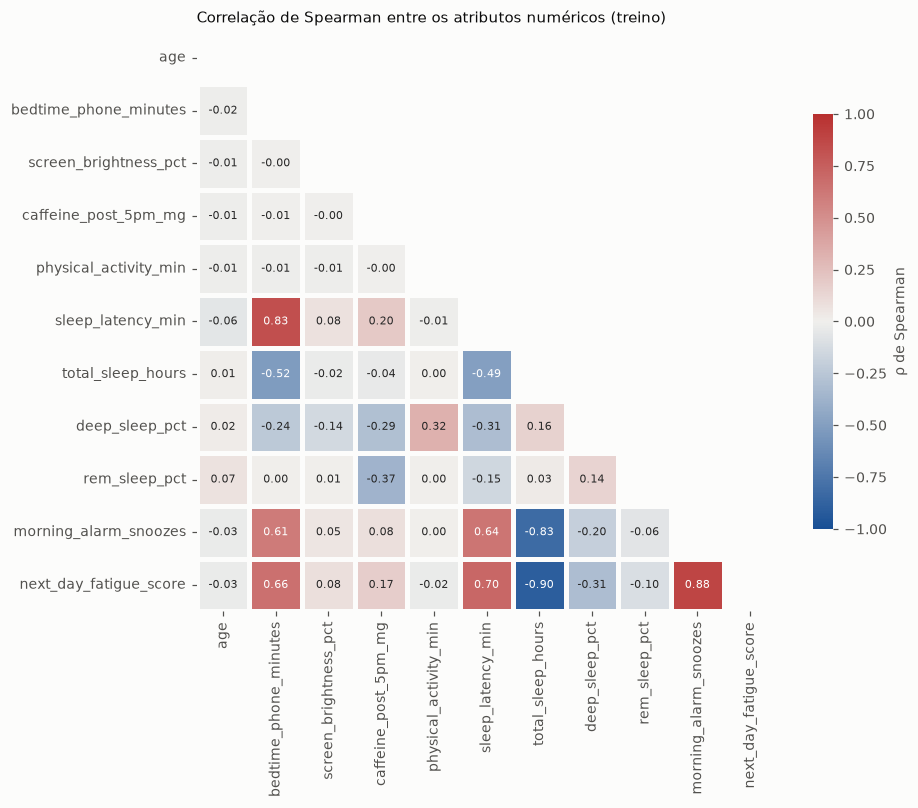

In [11]:
spearman = train[NUMERIC_COLS].corr(method="spearman")
mascara = np.triu(np.ones_like(spearman, dtype=bool))

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(spearman, mask=mascara, cmap=DIVERGENTE, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, linewidths=2, linecolor=SUPERFICIE, square=True,
            cbar_kws={"shrink": 0.7, "label": "ρ de Spearman"}, ax=ax)
ax.grid(False)
ax.set_title("Correlação de Spearman entre os atributos numéricos (treino)")
salvar(fig, "04_correlacao_numericas")

In [12]:
pearson = train[NUMERIC_COLS].corr(method="pearson")
pares = [(a, b) for i, a in enumerate(NUMERIC_COLS) for b in NUMERIC_COLS[i + 1:]]
comparacao = pd.DataFrame(
    [{"atributo 1": a, "atributo 2": b, "Pearson": pearson.loc[a, b], "Spearman": spearman.loc[a, b],
      "grupos": "comportamental" if GRUPOS[a] == GRUPOS[b] == "perfil e antes de dormir"
      else "sono" if GRUPOS[a] == GRUPOS[b] else "misto"}
     for a, b in pares]
)
comparacao["|Spearman|"] = comparacao["Spearman"].abs()
comparacao = comparacao[comparacao["|Spearman|"] >= 0.3].sort_values("|Spearman|", ascending=False)
comparacao.drop(columns="|Spearman|").round(3).reset_index(drop=True)

,atributo 1,atributo 2,Pearson,Spearman,grupos
0,total_sleep_hours,next_day_fatigue_score,-0.879,-0.899,sono
1,morning_alarm_snoozes,next_day_fatigue_score,0.881,0.884,sono
2,bedtime_phone_minutes,sleep_latency_min,0.858,0.829,misto
3,total_sleep_hours,morning_alarm_snoozes,-0.831,-0.825,sono
4,sleep_latency_min,next_day_fatigue_score,0.745,0.704,sono
5,bedtime_phone_minutes,next_day_fatigue_score,0.708,0.660,misto
6,sleep_latency_min,morning_alarm_snoozes,0.679,0.639,sono
7,bedtime_phone_minutes,morning_alarm_snoozes,0.648,0.608,misto
8,bedtime_phone_minutes,total_sleep_hours,-0.550,-0.519,misto
9,sleep_latency_min,total_sleep_hours,-0.526,-0.494,sono


- **Os atributos numéricos do cenário comportamental são praticamente independentes entre si** (|ρ| ≤ 0,02). Não há redundância a eliminar.
- As correlações fortes envolvem as colunas medidas durante o sono e no dia seguinte: `total_sleep_hours`, `morning_alarm_snoozes` e `next_day_fatigue_score` têm |ρ| entre 0,83 e 0,90 entre si.
- `bedtime_phone_minutes` é fortemente correlacionado com `sleep_latency_min` (ρ = 0,83) e moderadamente com `total_sleep_hours` (ρ = −0,52): na simulação, mais tempo de tela atrasa o início do sono e o encurta.
- Pearson e Spearman diferem em no máximo 0,05 nos pares listados, então as relações são aproximadamente lineares.

### 4.2 Atributos categóricos

A associação entre atributos categóricos é medida pelo **V de Cramér**, que vai de 0 (independência) a 1 (associação perfeita) e é calculado a partir da estatística qui-quadrado da tabela de contingência.

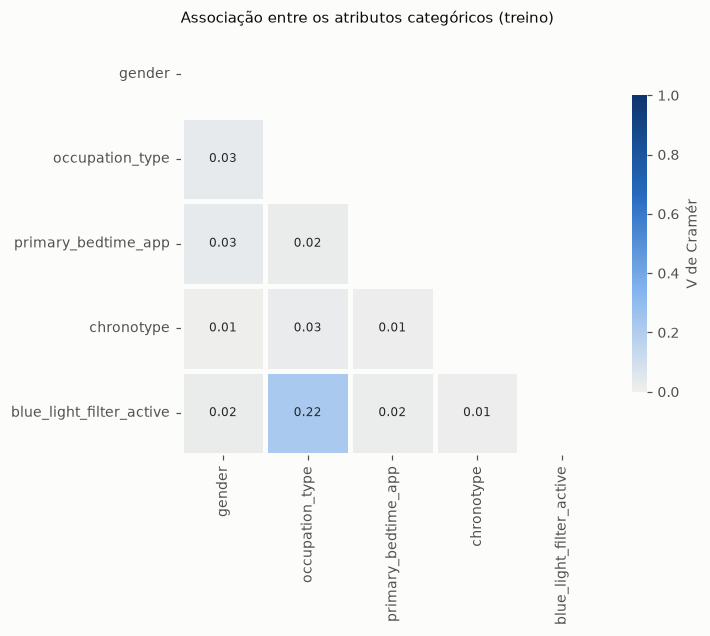

In [13]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    tabela = pd.crosstab(x, y).to_numpy()
    esperado = tabela.sum(axis=1, keepdims=True) * tabela.sum(axis=0, keepdims=True) / tabela.sum()
    qui2 = ((tabela - esperado) ** 2 / esperado).sum()
    return float(np.sqrt(qui2 / (tabela.sum() * (min(tabela.shape) - 1))))


cramer = pd.DataFrame(
    [[cramers_v(train[a], train[b]) for b in colunas_cat] for a in colunas_cat],
    index=colunas_cat, columns=colunas_cat,
)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cramer, mask=np.triu(np.ones_like(cramer, dtype=bool)), cmap=SEQUENCIAL, vmin=0, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=2, linecolor=SUPERFICIE, square=True,
            cbar_kws={"shrink": 0.7, "label": "V de Cramér"}, ax=ax)
ax.grid(False)
ax.set_title("Associação entre os atributos categóricos (treino)")
salvar(fig, "04_associacao_categoricas")

- As associações entre as categóricas são fracas. A única que se destaca é entre `occupation_type` e `blue_light_filter_active` (V = 0,22): `Remote Tech` e `Student` usam o filtro em cerca de 60% dos casos, e as demais ocupações em cerca de 37%.
- Somando as duas análises, a suposição de independência do Naive Bayes é razoável no cenário comportamental, mas não no completo, em que as colunas do sono são fortemente correlacionadas entre si.

## 5. Relação dos atributos com o alvo

### 5.1 Atributos numéricos

Como as classes do alvo são ordenadas, elas são codificadas de 0 (`Optimal Recovery`) a 3 (`Severe Sleep Debt`) para calcular a correlação de Spearman com cada atributo. Valores positivos indicam que o atributo cresce junto com o déficit de sono.

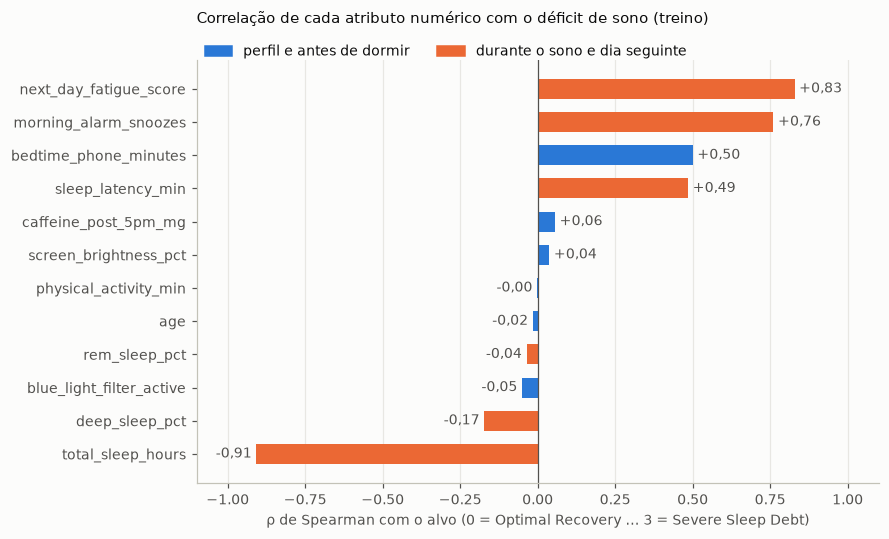

In [14]:
alvo_ordinal = train[TARGET].map({classe: i for i, classe in enumerate(TARGET_CLASSES)})
corr_alvo = train[NUMERIC_COLS + BINARY_COLS].corrwith(alvo_ordinal, method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(corr_alvo.index, corr_alvo, height=0.6,
                 color=[CORES_GRUPOS[GRUPOS[col]] for col in corr_alvo.index])
ax.bar_label(barras, labels=[f"{v:+.2f}".replace(".", ",") for v in corr_alvo], padding=3,
             color=TEXTO_SECUNDARIO)
ax.axvline(0, color=TEXTO_SECUNDARIO, linewidth=0.8)
ax.set_xlim(-1.1, 1.1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ρ de Spearman com o alvo (0 = Optimal Recovery … 3 = Severe Sleep Debt)")
ax.set_title("Correlação de cada atributo numérico com o déficit de sono (treino)", pad=24)
legenda_grupos(fig, loc="upper left", bbox_to_anchor=(0.12, 0.93))
salvar(fig, "04_correlacao_alvo")

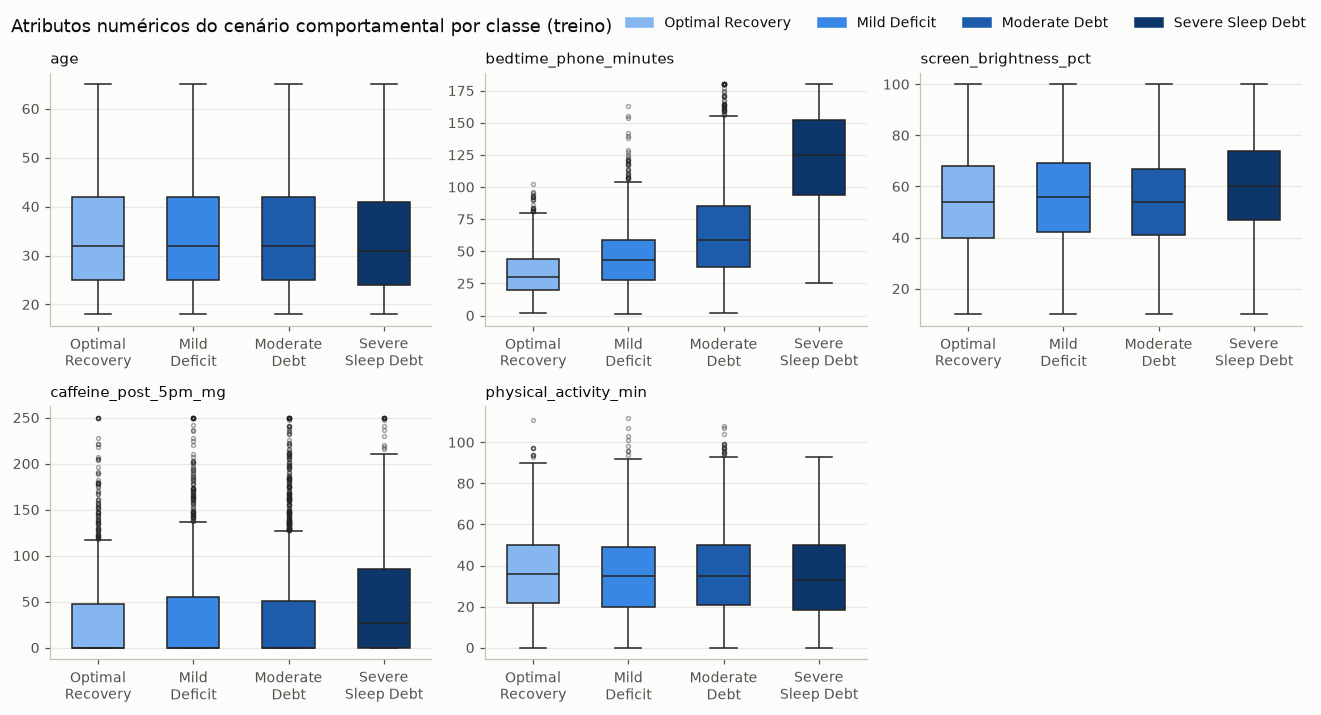

In [15]:
numericas_comportamentais = [col for col in NUMERIC_COLS if GRUPOS[col] == "perfil e antes de dormir"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.flat, numericas_comportamentais):
    sns.boxplot(data=train, x=TARGET, y=col, order=TARGET_CLASSES, hue=TARGET, hue_order=TARGET_CLASSES,
                palette=CORES_CLASSES, saturation=1, legend=False, width=0.55, linewidth=1, ax=ax,
                flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.4})
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
    ax.set_xticks(range(len(TARGET_CLASSES)), [c.replace(" ", "\n", 1) for c in TARGET_CLASSES])
axes.flat[-1].remove()
fig.suptitle("Atributos numéricos do cenário comportamental por classe (treino)", x=0.01, ha="left")
legenda_classes(fig, loc="upper right", bbox_to_anchor=(1, 1.0))
fig.tight_layout()
salvar(fig, "04_numericas_por_classe")

- As colunas do sono e do dia seguinte são as mais correlacionadas com o alvo (`total_sleep_hours`: ρ = −0,91; `next_day_fatigue_score`: ρ = 0,83), o que confirma o vazamento identificado na validação.
- No cenário comportamental, só `bedtime_phone_minutes` tem correlação forte (ρ = 0,50): a mediana sobe de 30 minutos em `Optimal Recovery` para 125 minutos em `Severe Sleep Debt`.
- `caffeine_post_5pm_mg` e `screen_brightness_pct` têm correlação quase nula, mas se diferenciam em `Severe Sleep Debt`: a mediana da cafeína é 27 mg nessa classe e 0 nas demais. Uma relação que só aparece numa classe extrema quase não muda a correlação, mas pode ser captada por uma árvore de decisão.
- `age` e `physical_activity_min` não mostram relação com o alvo.

### 5.2 Atributos categóricos

In [16]:
v_alvo = pd.Series({col: cramers_v(train[col], train[TARGET]) for col in colunas_cat}).sort_values(ascending=False)
v_alvo.round(3).to_frame("V de Cramér com o alvo")

,V de Cramér com o alvo
chronotype,0.408
occupation_type,0.143
blue_light_filter_active,0.067
primary_bedtime_app,0.050
gender,0.013


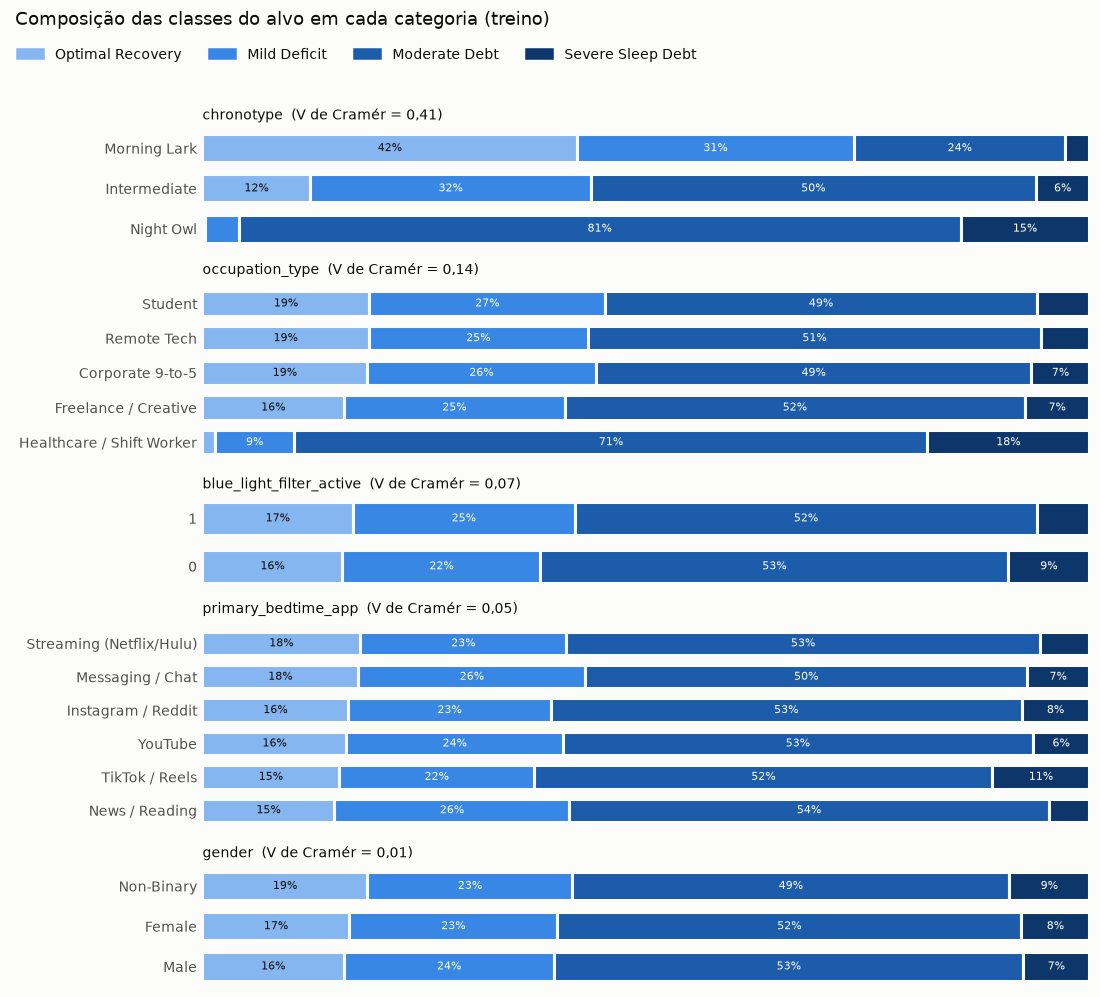

In [17]:
fig, axes = plt.subplots(len(v_alvo), 1, figsize=(10, 9),
                         gridspec_kw={"height_ratios": [train[c].nunique() + 1 for c in v_alvo.index]})
for ax, col in zip(axes, v_alvo.index):
    proporcoes = pd.crosstab(train[col], train[TARGET], normalize="index")[TARGET_CLASSES]
    proporcoes = proporcoes.reindex(ordem[col][::-1]) if col in ordem else proporcoes.sort_values("Optimal Recovery")
    esquerda = np.zeros(len(proporcoes))
    for classe in TARGET_CLASSES:
        valores = proporcoes[classe].to_numpy()
        barras = ax.barh(proporcoes.index.astype(str), valores, left=esquerda, height=0.7,
                         color=CORES_CLASSES[classe], edgecolor=SUPERFICIE, linewidth=2)
        cor_texto = TEXTO if classe == TARGET_CLASSES[0] else SUPERFICIE
        ax.bar_label(barras, labels=[pct(v, 0) if v >= 0.06 else "" for v in valores],
                     label_type="center", color=cor_texto, fontsize=7.5)
        esquerda += valores
    ax.set_xlim(0, 1)
    ax.set_title(f"{col}  (V de Cramér = {v_alvo[col]:.2f})".replace(".", ","), fontsize=9)
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
    ax.set_xticks([])
fig.suptitle("Composição das classes do alvo em cada categoria (treino)", x=0.01, y=1.0, ha="left")
legenda_classes(fig, loc="upper left", bbox_to_anchor=(0.0, 0.975))
fig.tight_layout(rect=(0, 0, 1, 0.95))
salvar(fig, "04_categoricas_por_classe")

- `chronotype` é o atributo categórico mais associado ao alvo (V = 0,41). Entre os `Night Owl`, só 5 de 1.942 estão em `Optimal Recovery` e 15% estão em `Severe Sleep Debt`; entre os `Morning Lark`, 42% estão em `Optimal Recovery`.
- Em `occupation_type` (V = 0,14), a associação vem de uma única categoria: `Healthcare / Shift Worker` tem 18% de `Severe Sleep Debt` e quase nenhum `Optimal Recovery`, e as outras ocupações têm composições parecidas.
- `blue_light_filter_active` e `primary_bedtime_app` têm associação fraca, visível só em `Severe Sleep Debt`: 9% sem o filtro e 6% com ele; 11% entre quem usa `TikTok / Reels`.
- `gender` não tem relação com o alvo (V = 0,01).

## Conclusões para o pré-processamento

| Achado | Decisão para a etapa 5 |
|---|---|
| Classes desbalanceadas (52,5% × 7,6%) | Avaliar com acurácia balanceada e F1 macro; testar `class_weight="balanced"` na árvore |
| Outliers reais, dentro do domínio | Manter todos os registros; testar `log1p` em `bedtime_phone_minutes`, `caffeine_post_5pm_mg` e `sleep_latency_min` no KNN e no Naive Bayes |
| Escalas muito diferentes (minutos, mg, %, anos) | Padronizar as numéricas no KNN; desnecessário na árvore |
| `chronotype` tem ordem natural | Codificação ordinal (`Morning Lark` < `Intermediate` < `Night Owl`) |
| Nominais sem ordem, `Non-Binary` com 2,9% | One-hot no KNN e no Naive Bayes, mantendo todas as categorias |
| Atributos comportamentais independentes entre si | Nenhuma remoção por redundância no cenário comportamental |
| Colunas do sono fortemente correlacionadas entre si | Violam a independência do Naive Bayes no cenário completo, que serve só de comparação |
| Sinais concentrados em `Severe Sleep Debt` (cafeína, brilho, ocupação) | Relações não lineares, que a árvore capta melhor que o KNN e o Naive Bayes |

No cenário comportamental, os atributos com mais sinal são `chronotype`, `bedtime_phone_minutes` e `occupation_type`; os demais têm relação fraca ou nula com o alvo. No cenário completo, `total_sleep_hours` sozinho tem ρ = −0,91 com o alvo, então a diferença de desempenho entre os dois cenários deve ser grande.